## Context

This notebook accompanies User Guide section 14 (Workflow planner).  It builds a `WorkflowPlanner` over the prebuilt fixture, generates a plan via `next_step` and `full_plan`, validates it, then compares three competing plan strategies — GMS-guided, hardcoded sequential, random shuffle — side by side.  After calibration via `planner.calibrate`, the same three plans are re-validated and the verdict `accept`/`review`/`reject` is read directly from `PlanValidation`.  Reading the holonomy-defect bar chart tells you whether the planner geometry is discriminating between sane and adversarial orderings.

In [1]:
# Phase 3c preamble: bootstrap runtime + load shared helpers
import sys
import os
import glob
import warnings
warnings.filterwarnings('ignore')
for _p in glob.glob(
        '/home/asudjianto/cluster/spark-venv/lib/python*/site-packages'):
    if _p not in sys.path:
        sys.path.insert(0, _p)
_REPO = os.path.expanduser('~/jupyterlab/kg-memory')
if _REPO not in sys.path:
    sys.path.insert(0, _REPO)

from user_guide_tutorials.notebooks import _helpers_phase1 as h1
h1.bootstrap_runtime()  # idempotent; also stubs modeva if absent
from user_guide_tutorials.notebooks import _shared as ug
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')


Device: cuda, CUDA available: True


### Concept: two attestors must both accept

`WorkflowPlanner` is a thin wrapper around three GMS primitives.  `link_predict("precedes")` ranks candidate next steps; `check_holonomy` measures whether the composed `precedes` rotor along the plan agrees with the direct edge; `query_triples` over `requires` resolves prerequisites.  The planner adds no geometry of its own — it is a recipe for interrogating the store.

`PlanValidation` always carries three baseline fields: `holonomy` (lower is better; a long inconsistent plan scores high), `prerequisites_satisfied` (a hard boolean from the prerequisite table), and `violations` (human-readable strings naming each prerequisite miss).  Calibration adds three more fields by fitting a logistic classifier on six features extracted from the plan: `holonomy`, `n_violations`, `n_unknown_steps`, `core_coverage`, `mean_precedes_score`, `plan_length_delta`.  The classifier emits `prob_valid`, `tau_accept`, `tau_reject` partition that probability into three verdicts: `accept` (release for execution), `review` (human in the loop), `reject` (block).

A second declarative attestor catches what geometry should not be trusted to learn.  `PlanPolicy` is an AND-gated rule pack — eleven rules, ten blocking, one advisory.  After `attach_policy`, `PlanValidation` carries `policy_verdict` and `policy_reasons`.  A plan is released for execution only when both the calibrated and the policy verdicts are `accept`.

We compare three strategies.  The GMS-guided plan is what `full_plan(goal="deploy")` produces.  The hardcoded sequential plan is the canonical ordering from `governed_agent.planner.CANONICAL_ORDER`.  The random plan is a shuffle of the canonical steps.  We expect the first two to accept and the third to trigger either `review` or `reject`.

In [ ]:
from knowlytix.harness.governance.planner import (
    WorkflowPlanner, CANONICAL_ORDER,
)
from knowlytix.harness.governance.plan_policy import (
    PlanPolicy, data_science_rules,
)
from knowlytix.harness.governance.plan_benchmark import build_cohort

store = ug.load_ds_practices_store()
planner = WorkflowPlanner(store, device=DEVICE)
print(planner)


In [3]:
# next_step + full_plan
step = planner.next_step(
    completed_steps=['load_data'],
    context='ds_practices_store',
)
print(f'next_step after load_data: '
      f'tool={step.tool!r} conf={step.confidence:.2f}')
print(f'reason: {step.reason}')

gms_plan_steps = planner.full_plan(
    goal='deploy',
    context='ds_practices_store',
    max_steps=14,
)
gms_plan = [s.tool for s in gms_plan_steps]
print()
print('GMS-guided plan:')
for i, p in enumerate(gms_plan_steps):
    print(f'  {i+1:2d}. {p.tool:24s} '
          f'conf={p.confidence:.2f}')


next_step after load_data: tool='preprocess_data' conf=0.50
reason: Canonical fallback after load_data; prerequisites satisfied.

GMS-guided plan:
   1. load_data                conf=0.80
   2. preprocess_data          conf=0.50
   3. feature_select           conf=0.50
   4. train_model              conf=0.50
   5. diagnose_accuracy        conf=0.50
   6. diagnose_robustness      conf=0.50
   7. diagnose_fairness        conf=0.50
   8. explain_importance       conf=0.50
   9. explain_pdp              conf=0.50
  10. explain_shap             conf=0.50
  11. compare_models           conf=0.50
  12. release_gate             conf=0.50
  13. deploy                   conf=0.50


In [4]:
# Three strategies for the same problem
import random
rng = random.Random(0)

hardcoded_plan = list(CANONICAL_ORDER)
random_plan = list(CANONICAL_ORDER)
rng.shuffle(random_plan)

strategies = [
    ('gms_guided',  gms_plan),
    ('hardcoded',   hardcoded_plan),
    ('random',      random_plan),
]
for name, plan in strategies:
    print(f'{name:11s} ({len(plan)} steps): {plan}')


gms_guided  (13 steps): ['load_data', 'preprocess_data', 'feature_select', 'train_model', 'diagnose_accuracy', 'diagnose_robustness', 'diagnose_fairness', 'explain_importance', 'explain_pdp', 'explain_shap', 'compare_models', 'release_gate', 'deploy']
hardcoded   (13 steps): ['load_data', 'preprocess_data', 'feature_select', 'train_model', 'diagnose_accuracy', 'diagnose_robustness', 'diagnose_fairness', 'explain_importance', 'explain_pdp', 'explain_shap', 'compare_models', 'release_gate', 'deploy']
random      (13 steps): ['preprocess_data', 'compare_models', 'explain_shap', 'diagnose_robustness', 'release_gate', 'feature_select', 'train_model', 'explain_importance', 'explain_pdp', 'diagnose_accuracy', 'load_data', 'deploy', 'diagnose_fairness']


In [5]:
# Baseline validation: holonomy + prereqs (uncalibrated)
baseline = {}
for name, plan in strategies:
    v = planner.validate_plan(plan)
    baseline[name] = v
    print(f'{name:11s}  holonomy={v.holonomy:.4f}  '
          f'prereqs={v.prerequisites_satisfied}  '
          f'violations={len(v.violations)}')


gms_guided   holonomy=0.0000  prereqs=True  violations=0
hardcoded    holonomy=0.0000  prereqs=True  violations=0
random       holonomy=0.6667  prereqs=False  violations=4


In [6]:
# Calibrate on the deterministic plan benchmark
cohort = build_cohort(seed=42)
print(f'cohort size: {len(cohort)}')
metrics = planner.calibrate(cohort, seed=42)
print(f'tau_accept = {metrics["tau_accept"]:.3f}, '
      f'tau_reject = {metrics["tau_reject"]:.3f}')
print(f'FPR = {metrics["fpr"]:.3f}  '
      f'(95% CI {metrics["fpr_ci"][0]:.3f} - '
      f'{metrics["fpr_ci"][1]:.3f})')
print(f'FNR = {metrics["fnr"]:.3f}  '
      f'(95% CI {metrics["fnr_ci"][0]:.3f} - '
      f'{metrics["fnr_ci"][1]:.3f})')


cohort size: 400
tau_accept = 0.650, tau_reject = 0.350
FPR = 0.052  (95% CI 0.011 - 0.101)
FNR = 0.000  (95% CI 0.000 - 0.000)


In [7]:
# Attach the declarative co-attestor
planner.attach_policy(PlanPolicy(data_science_rules()))
print('Policy attached: 11 rules '
      '(10 blocking, 1 advisory).')


Policy attached: 11 rules (10 blocking, 1 advisory).


In [8]:
# Re-validate every strategy with calibration + policy
calibrated = {}
for name, plan in strategies:
    v = planner.validate_plan(plan)
    calibrated[name] = v
    print(f'{name:11s}  '
          f'verdict={v.verdict!s:7s}  '
          f'conf={v.confidence:.3f}  '
          f'policy={v.policy_verdict!s:7s}')
    if v.policy_reasons:
        for r in v.policy_reasons[:3]:
            print(f'    - {r}')


gms_guided   verdict=accept   conf=0.847  policy=accept 
hardcoded    verdict=accept   conf=0.847  policy=accept 
random       verdict=reject   conf=0.000  policy=reject 
    - R4-diag-requires-train: any diagnostic step must follow train_model
    - R8-explain-requires-train: explanation steps must follow train_model


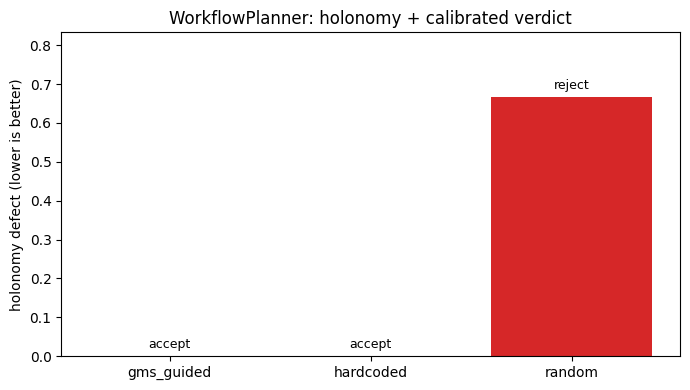

In [9]:
# Visualization: holonomy defect per strategy + verdict
import matplotlib.pyplot as plt

names = [name for name, _ in strategies]
holos = [calibrated[n].holonomy for n in names]
verdicts = [calibrated[n].verdict for n in names]
verdict_color = {
    'accept': 'tab:green',
    'review': 'tab:olive',
    'reject': 'tab:red',
    None:     'tab:gray',
}
colors = [verdict_color.get(v, 'tab:gray') for v in verdicts]

fig, ax = plt.subplots(figsize=(7.0, 4.0))
bars = ax.bar(names, holos, color=colors)
for b, v in zip(bars, verdicts):
    ax.text(b.get_x() + b.get_width() / 2,
            b.get_height() + max(holos) * 0.02,
            str(v), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('holonomy defect (lower is better)')
ax.set_title('WorkflowPlanner: holonomy + calibrated verdict')
ax.set_ylim(0, max(holos) * 1.25 if max(holos) > 0 else 1.0)
fig.tight_layout()
plt.show()


### Exercises

1. Construct a fourth plan that ends in `release_gate` but omits `diagnose_fairness`.  Predict which attestor rejects it (R6 of the rule pack, or the calibrated geometric verdict).  Verify by inspecting `PlanValidation.policy_reasons`.
2. Re-run the calibration with `review_band=0.30` instead of the default 0.15.  Does the random plan now land in `review` instead of `reject`?  What does that say about the cost of widening the review band in production?
3. Pick one rule from `data_science_rules()` and read its predicate.  Construct a plan that the geometric attestor would accept but the policy attestor must reject (or the other way around).

### What you should now be able to do

- Recommend a single next step with `planner.next_step`   and a full plan with `planner.full_plan`.
- Read `PlanValidation.holonomy`, `verdict`,   `confidence`, `policy_verdict`, and `policy_reasons`   to release-or-block a candidate plan.
- Calibrate the planner against a labeled cohort and   read the held-out FPR / FNR with bootstrap CIs.
- Attach a `PlanPolicy` co-attestor and require both   the calibrated verdict and the policy verdict to   accept before execution.

### Cross-references

- USER_GUIDE.md section 14 (Workflow planner)
- `governed_agent/planner.py:WorkflowPlanner` and   `governed_agent/plan_policy.py:PlanPolicy`
- `gms_agent_builder_ext/chapters/ch09.tex` for the   planner in book form
- §17 Behavioral contracts — for the trace-level   analogue of plan validation.

In [10]:
# Final assertion: GMS plan + hardcoded plan accept;
# random plan rejects (or, at worst, requires review).
v_gms  = calibrated['gms_guided']
v_hard = calibrated['hardcoded']
v_rand = calibrated['random']

assert v_gms.verdict == 'accept', (
    f'gms_guided plan should accept; got '
    f'verdict={v_gms.verdict} conf={v_gms.confidence}'
)
assert v_hard.verdict == 'accept', (
    f'hardcoded plan should accept; got '
    f'verdict={v_hard.verdict} conf={v_hard.confidence}'
)
assert v_rand.verdict in {'reject', 'review'}, (
    f'random plan must not auto-accept; got '
    f'verdict={v_rand.verdict} conf={v_rand.confidence}'
)
print(f'OK: gms={v_gms.verdict}, '
      f'hardcoded={v_hard.verdict}, '
      f'random={v_rand.verdict}')


OK: gms=accept, hardcoded=accept, random=reject
